# Resumes data test

- test multiple clustering methods
- see if there are interesting results

## DATA + Embedding + Normalization + PCA

In [ ]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt

# Set all random seeds
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

#https://www.kaggle.com/datasets/anselerol/job-postings-and-resumes-with-embeddings-faiss?resource=download
df = pd.read_csv('../data/resumes.csv')
df['name'] = df['text'].apply(lambda x: x.split('Summary')[0].strip())
# Sort dataframe by 'id' to ensure consistent ordering
df = df.sort_values('id').reset_index(drop=True)
print(f"✓ Random seeds set to {RANDOM_SEED}")
print(f"✓ DataFrame sorted by 'id' and reset: {len(df)} rows")

✓ Random seeds set to 42
✓ DataFrame sorted by 'id' and reset: 2484 rows


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         2484 non-null   int64 
 1   text       2484 non-null   object
 2   name       2484 non-null   object
 3   embedding  2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB


In [ ]:
df.head()

,id,text,name,embedding
0,1,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,"[-0.04447828233242035, 0.021229209378361702, 0..."
1,2,"HR SPECIALIST, US HR OPERATIONS ...","HR SPECIALIST, US HR OPERATIONS","[-0.05166391283273697, 0.01624675653874874, 0...."
2,3,HR DIRECTOR Summary Over 2...,HR DIRECTOR,"[-0.04784499853849411, 0.019322028383612633, -..."
3,4,HR SPECIALIST Summary Dedica...,HR SPECIALIST,"[-0.10490810126066208, 0.011350762099027634, 0..."
4,5,HR MANAGER Skill Highlights ...,HR MANAGER Skill Highlights ...,"[-0.06549879908561707, 0.04003952443599701, -0..."


In [ ]:
from sklearn.preprocessing import StandardScaler, normalize
import ast  # Pour convertir les chaînes en listes si nécessaire

# Conversion des embeddings si stockés en chaîne
def convert_embedding(embedding_str):
    """Convertit une chaîne en liste numpy array"""
    if isinstance(embedding_str, str):
        return np.array(ast.literal_eval(embedding_str))
    elif isinstance(embedding_str, list):
        return np.array(embedding_str)
    else:
        return embedding_str

# Appliquer la conversion
df['embeddings_array'] = df['embedding'].apply(convert_embedding)

# Vérifier la dimension des embeddings
embedding_dim = len(df['embeddings_array'].iloc[0])
print(f"Dimension des embeddings : {embedding_dim}")

# Créer la matrice d'embeddings => c'est sur cette matrice qu'on va calculer les clusters
embeddings_matrix = np.vstack(df['embeddings_array'].values)
print(f"Shape de la matrice d'embeddings : {embeddings_matrix.shape}")

# Normaliser les données
scaler = StandardScaler()
#embeddings_matrix_normalized = scaler.fit_transform(embeddings_matrix)
embeddings_matrix_normalized = normalize(embeddings_matrix, norm='l2')

Dimension des embeddings : 384
Shape de la matrice d'embeddings : (2484, 384)


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=min(50, embedding_dim), random_state=RANDOM_SEED)  # Added random_state for reproducibility
embeddings_reduced = pca.fit_transform(embeddings_matrix_normalized)
print(f"Variance expliquée par les {pca.n_components_} composantes : {pca.explained_variance_ratio_.sum():.2%}")

Variance expliquée par les 50 composantes : 65.80%


## KMeans

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

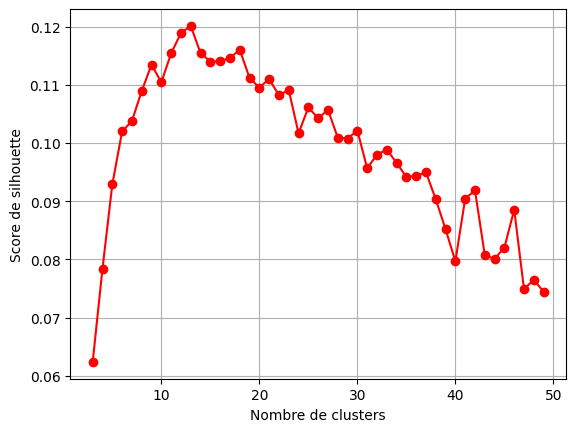

In [ ]:
# 3. DÉTERMINATION DU NOMBRE OPTIMAL DE CLUSTERS (score de silhouette)
silhouette_scores = []
K_range = range(2, 50)  # Tester de 2 à 14 clusters

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(embeddings_reduced)
    #inertias.append(kmeans.inertia_)

    if k > 1:  # silhouette_score nécessite au moins 2 clusters
        score = silhouette_score(embeddings_reduced, kmeans.labels_)
        silhouette_scores.append(score)
    else:
        silhouette_scores.append(0)

plt.plot(K_range[1:], silhouette_scores[1:], 'ro-')
plt.xlabel('Nombre de clusters')
plt.ylabel('Score de silhouette')
plt.grid(True)
plt.show()

In [ ]:
# 4. CLUSTERING AVEC K-MEANS (choisir k optimal)
optimal_k = 12  #Par exemple
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
cluster_labels = kmeans.fit_predict(embeddings_reduced)

df['cluster'] = cluster_labels

# 5. ANALYSE DES CLUSTERS
# Statistiques par cluster
cluster_stats = df.groupby('cluster').agg({
    'id': 'count',
    #'source': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'N/A',
    #'date': ['min', 'max']
}).round(2)

<Axes: xlabel='cluster'>

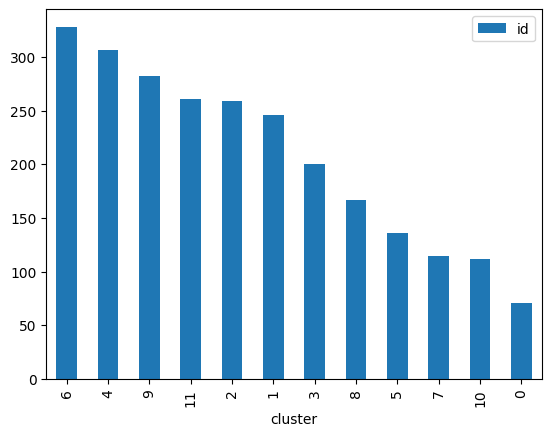

In [ ]:
cluster_stats = cluster_stats.sort_values(by='id', ascending=False)  # si la colonne s'appelle 'title'
cluster_stats.plot(kind='bar')

In [ ]:
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Télécharger les stop words français si nécessaire
nltk.download('stopwords')
english_stop_words = stopwords.words('english')

# Add custom stopwords for resume-specific noise
custom_stopwords = list(english_stop_words) + [
    'company', 'january', 'february', 'march', 'april', 'may', 'june',
    'july', 'august', 'september', 'october', 'november', 'december',
    'present', 'summary', 'experience', 'responsibilities', 'duties',
    'including', 'worked', 'years', 'responsible', 'various', 'multiple',
    'excellent', 'great', 'good', 'provided', 'ensured', 'created'
]

def extract_keywords_by_cluster(texts, labels, n_keywords=10):
    """Extrait les mots-clés TF-IDF par cluster"""
    unique_labels = np.unique(labels)
    keywords_by_cluster = {}

    for label in unique_labels:
        cluster_texts = [texts[i] for i in range(len(texts)) if labels[i] == label]

        if len(cluster_texts) < 2:
            keywords_by_cluster[label] = ["peu_de_documents"]
            continue

        # CRÉER UN NOUVEAU VECTORIZER POUR CHAQUE CLUSTER
        vectorizer = TfidfVectorizer(
            max_features=100,
            stop_words=custom_stopwords,
            ngram_range=(1, 3),  # Unigrams, bigrams and trigrams
            min_df=3,  # Mot doit apparaître dans au moins 3 docs du cluster
            max_df=0.5,  # Éliminer les mots apparaissant dans > 50% des docs
            token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b'  # Au moins 2 lettres
        )

        try:
            tfidf_matrix = vectorizer.fit_transform(cluster_texts)
            feature_names = vectorizer.get_feature_names_out()

            if len(feature_names) == 0:
                keywords_by_cluster[label] = ["aucun_mot"]
                continue

            tfidf_scores = tfidf_matrix.mean(axis=0).A1
            top_indices = tfidf_scores.argsort()[-n_keywords:][::-1]
            top_keywords = [feature_names[i] for i in top_indices]
            keywords_by_cluster[label] = top_keywords

        except Exception as e:
            keywords_by_cluster[label] = [f"erreur: {str(e)[:30]}"]

    return keywords_by_cluster

# Utiliser la colonne 'text' ou 'chunk_text' pour l'extraction
texts = df['text'].fillna('').astype(str).tolist()
keywords_by_cluster = extract_keywords_by_cluster(texts, cluster_labels, n_keywords=4)

print("\nMots-clés par cluster :")
for cluster in sorted(keywords_by_cluster.keys()):
    keywords = keywords_by_cluster[cluster]
    print(f"Cluster {cluster}: {', '.join(keywords)}")

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/khaledbouabdallah/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



Mots-clés par cluster :
Cluster 0: wellness, customer service, member, equipment
Cluster 1: sql, database, engineering, servers
Cluster 2: sales, customer service, program, client
Cluster 3: press, event, strategy, client
Cluster 4: tax, payroll, credit, ledger
Cluster 5: customer service, sales, staffing, candidates
Cluster 6: construction, design, production, aviation
Cluster 7: executive chef, catering, cook, chef name
Cluster 8: children, service, grade, academic
Cluster 9: cash, merchandise, client, clients
Cluster 10: graphic, interior, marketing, art
Cluster 11: accounts, account, data, customer service


In [ ]:
# For each cluster, randomly pick 5 sample resumes
np.random.seed(RANDOM_SEED)  # For reproducibility

print("\n" + "="*80)
print("SAMPLE RESUMES BY CLUSTER")
print("="*80)

for cluster_id in sorted(df['cluster'].unique()):
    cluster_df = df[df['cluster'] == cluster_id]
    n_samples = min(10, len(cluster_df))  # Take 3 samples or fewer if cluster is small

    samples = cluster_df.sample(n=n_samples, random_state=RANDOM_SEED)

    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id} - Keywords: {', '.join(keywords_by_cluster[cluster_id])}")
    print(f"Total resumes: {len(cluster_df)}")
    print(f"{'='*80}\n")

    for idx, (_, row) in enumerate(samples.iterrows(), 1):
        # Extract first 400 characters for preview
        text_preview = row['text'][:400].replace('\n', ' ')
        print(f"Sample {idx}:")
        print(f"  Name: {row['name'][:50]}")
        print(f"  Preview: {text_preview}...")
        print()


SAMPLE RESUMES BY CLUSTER

CLUSTER 0 - Keywords: wellness, customer service, member, equipment
Total resumes: 71

Sample 1:
  Name: FITNESS TRAINER           Professional
  Preview:          FITNESS TRAINER           Professional Summary     Articulate Certified Personal Trainer driven to succeed. Strategic planning and client relationship management expert.  Looking to advance my career here at Planet Fitness and take my member oriented approach to a reach a much larger scale of members.       Core Qualifications          Very broad background in Fitness Industry.  Graduated...

Sample 2:
  Name: ASSISTANT FOOTBALL COACH
  Preview:          ASSISTANT FOOTBALL COACH       Summary    Enthusiastic, reliable recent graduate with academic background in business and marketing. Ability to establish priorities and meet challenges head-on. Strong leadership and management skills. Seeking a career in the business field.      Highlights        Exceptional interpersonal communication skills, Cus

Computing t-SNE projection...
Computing UMAP projection...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


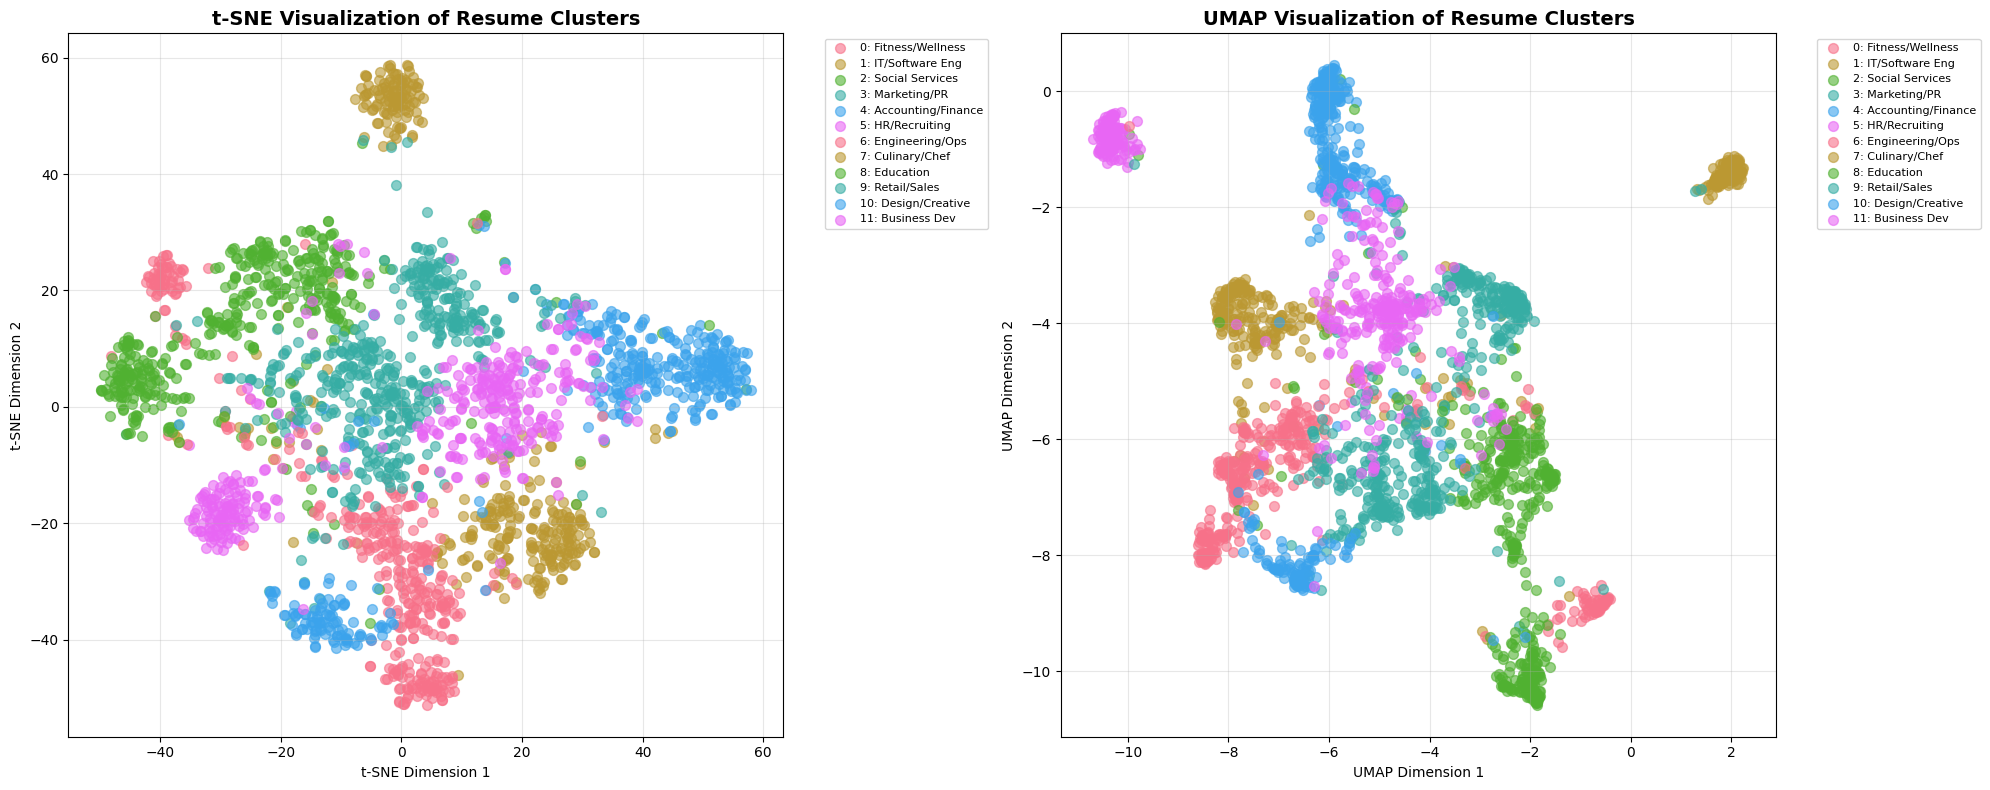

In [ ]:
from sklearn.manifold import TSNE
import umap
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plot style
plt.style.use('default')
sns.set_palette("husl")

# Create figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Define cluster names for better visualization
cluster_names = {
    0: "Fitness/Wellness",
    1: "IT/Software Eng",
    2: "Social Services",
    3: "Marketing/PR",
    4: "Accounting/Finance",
    5: "HR/Recruiting",
    6: "Engineering/Ops",
    7: "Culinary/Chef",
    8: "Education",
    9: "Retail/Sales",
    10: "Design/Creative",
    11: "Business Dev"
}

# 1. t-SNE visualization
print("Computing t-SNE projection...")
tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=30, n_iter_without_progress=1000)
embeddings_tsne = tsne.fit_transform(embeddings_reduced)

# Plot t-SNE
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    axes[0].scatter(
        embeddings_tsne[mask, 0],
        embeddings_tsne[mask, 1],
        label=f"{cluster_id}: {cluster_names[cluster_id]}",
        alpha=0.6,
        s=50
    )

axes[0].set_title('t-SNE Visualization of Resume Clusters', fontsize=14, fontweight='bold')
axes[0].set_xlabel('t-SNE Dimension 1')
axes[0].set_ylabel('t-SNE Dimension 2')
axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[0].grid(True, alpha=0.3)

# 2. UMAP visualization
print("Computing UMAP projection...")
umap_model = umap.UMAP(n_components=2, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1)
embeddings_umap = umap_model.fit_transform(embeddings_reduced)

# Plot UMAP
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    axes[1].scatter(
        embeddings_umap[mask, 0],
        embeddings_umap[mask, 1],
        label=f"{cluster_id}: {cluster_names[cluster_id]}",
        alpha=0.6,
        s=50
    )

axes[1].set_title('UMAP Visualization of Resume Clusters', fontsize=14, fontweight='bold')
axes[1].set_xlabel('UMAP Dimension 1')
axes[1].set_ylabel('UMAP Dimension 2')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 3D Interactive visualization using plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Compute 3D projections
print("Computing 3D t-SNE projection...")
tsne_3d = TSNE(n_components=3, random_state=RANDOM_SEED, perplexity=30, n_iter_without_progress=1000)
embeddings_tsne_3d = tsne_3d.fit_transform(embeddings_reduced)

print("Computing 3D UMAP projection...")
umap_3d = umap.UMAP(n_components=3, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1)
embeddings_umap_3d = umap_3d.fit_transform(embeddings_reduced)

# Create subplots
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]],
    subplot_titles=('3D t-SNE Visualization', '3D UMAP Visualization')
)

# Color palette
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b',
          '#e377c2', '#7f7f7f', '#bcbd22', '#17becf', '#aec7e8', '#ffbb78']

# Add t-SNE traces
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=embeddings_tsne_3d[mask, 0],
            y=embeddings_tsne_3d[mask, 1],
            z=embeddings_tsne_3d[mask, 2],
            mode='markers',
            name=f"{cluster_id}: {cluster_names[cluster_id]}",
            marker=dict(size=4, color=colors[cluster_id], opacity=0.7),
            text=[cluster_names[cluster_id]] * mask.sum(),
            hovertemplate='<b>%{text}</b><br>X: %{x:.2f}<br>Y: %{y:.2f}<br>Z: %{z:.2f}<extra></extra>'
        ),
        row=1, col=1
    )

# Add UMAP traces
for cluster_id in sorted(df['cluster'].unique()):
    mask = df['cluster'] == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=embeddings_umap_3d[mask, 0],
            y=embeddings_umap_3d[mask, 1],
            z=embeddings_umap_3d[mask, 2],
            mode='markers',
            name=f"{cluster_id}: {cluster_names[cluster_id]}",
            marker=dict(size=4, color=colors[cluster_id], opacity=0.7),
            text=[cluster_names[cluster_id]] * mask.sum(),
            hovertemplate='<b>%{text}</b><br>X: %{x:.2f}<br>Y: %{y:.2f}<br>Z: %{z:.2f}<extra></extra>',
            showlegend=False  # Avoid duplicate legends
        ),
        row=1, col=2
    )

# Update layout
fig.update_layout(
    title_text="3D Interactive Cluster Visualizations",
    height=700,
    showlegend=True,
    legend=dict(
        yanchor="top",
        y=0.99,
        xanchor="left",
        x=0.01,
        font=dict(size=9)
    )
)

fig.show()

Computing 3D t-SNE projection...
Computing 3D UMAP projection...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

In [ ]:
cluster_names = {
    0: "Fitness/Wellness",
    1: "IT/Software Eng",
    2: "Social Services",
    3: "Marketing/PR",
    4: "Accounting/Finance",
    5: "HR/Recruiting",
    6: "Engineering/Ops",
    7: "Culinary/Chef",
    8: "Education",
    9: "Retail/Sales",
    10: "Design/Creative",
    11: "Business Dev"
}

templates = [
    "What skills does a {job_title} need?",
    "What is the average salary for a {job_title}?",
    "What education is required for a {job_title}?",
]

In [ ]:

model_name = "mistralai/Mistral-7B-Instruct-v0.2"

# Create quantization config
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",  # Normal Float 4 (recommended)
    bnb_4bit_compute_dtype=torch.bfloat16,  # Compute in bf16 for speed
    bnb_4bit_use_double_quant=True,  # Extra memory savings
)

# Load model with optimizations
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,  # Better performance
    low_cpu_mem_usage=True,       # Memory optimization
)

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Configure tokenizer for batching
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"  # Important for causal LM generation

model.eval()

print(f"✓ Model loaded on device: {model.device}")
print(f"✓ Model dtype: {model.dtype}")


Loading checkpoint shards: 100%|██████████| 3/3 [00:26<00:00,  8.72s/it]



✓ Model loaded on device: cuda:0
✓ Model dtype: torch.bfloat16


In [ ]:
# Check if model is already loaded and clear GPU memory
import gc

# Check GPU memory before loading
if torch.cuda.is_available():
    print(f"\nGPU Memory status:")
    print(f"  Total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"  Allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
    print(f"  Reserved: {torch.cuda.memory_reserved() / 1e9:.2f} GB")
    print(f"  Free: {(torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_reserved()) / 1e9:.2f} GB")

    # Set PyTorch memory allocator to be more aggressive about releasing memory
    import os
    os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
    print(f"✓ Set PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True\n")


GPU Memory status:
  Total: 16.60 GB
  Allocated: 4.14 GB
  Reserved: 12.90 GB
  Free: 3.70 GB
✓ Set PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True



In [ ]:
from tqdm import tqdm
import json
import gc

def generate_questions_with_logits_batched(df, model, tokenizer, templates, cluster_names, batch_size=8):
    """
    Generate questions with batching for much faster GPU utilization.
    Includes proper GPU memory management.

    Returns a list of dictionaries containing:
    - job_name: the job title
    - cluster: cluster ID
    - cluster_name: semantic cluster name
    - question_idx: which question template (0, 1, or 2)
    - question: the full question text
    - generated_answer: the LLM's response
    - token_logits: list of max logit for each generated token
    - avg_confidence: average of token-level confidences
    """
    results = []

    # Prepare all questions upfront with direct prompting
    all_data = []
    for idx, row in df.iterrows():
        job_name = row['name']
        cluster_id = row['cluster']
        cluster_name = cluster_names.get(cluster_id, f"Cluster {cluster_id}")

        for q_idx, template in enumerate(templates):
            base_question = template.format(job_title=job_name)

            # Use simple direct format - just question + directive
            # Simpler is better to avoid the model echoing format tokens
            question = f"{base_question}\nProvide a direct answer:"

            all_data.append({
                'job_name': job_name,
                'cluster': cluster_id,
                'cluster_name': cluster_name,
                'question_idx': q_idx,
                'question': base_question,  # Store original question
                'prompt': question  # Store formatted prompt
            })
    print(f"Prepared {len(all_data)} questions to process in batches of {batch_size}")

    # Clear GPU memory before starting
    torch.cuda.empty_cache()
    gc.collect()

    # Process in batches
    for i in tqdm(range(0, len(all_data), batch_size), desc="Generating answers (batched)"):
        batch = all_data[i:i + batch_size]
        prompts = [item['prompt'] for item in batch]  # Use formatted prompts

        # Tokenize batch with padding
        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512
        ).to(model.device)

        # Generate for batch
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=100,  # Reduced from 100 for speed
                output_scores=True,
                return_dict_in_generate=True,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id
            )

        # Process each item in batch
        for j, item in enumerate(batch):
            # Extract token-level logits for this sample
            token_logits = []
            for score in outputs.scores:
                max_prob = torch.softmax(score[j], dim=-1).max().item()
                token_logits.append(max_prob)

            avg_confidence = sum(token_logits) / len(token_logits) if token_logits else 0.0

            # Find where the input ends (skip padding)
            input_length = inputs.attention_mask[j].sum().item()
            generated_tokens = outputs.sequences[j][input_length:]
            generated_answer = tokenizer.decode(generated_tokens, skip_special_tokens=True)


            # Strip common unwanted prefixes that models often add
            unwanted_prefixes = ['Answer:', 'answer:', '] Answer:', ']', ': ', 'A: ', '\n']
            for prefix in unwanted_prefixes:
                if generated_answer.startswith(prefix):
                    generated_answer = generated_answer[len(prefix):].lstrip()

            results.append({
                **item,
                'generated_answer': generated_answer.strip(),
                'token_logits': token_logits,
                'avg_confidence': avg_confidence,
                'num_tokens': len(token_logits)
            })
# Clear any existing GPU memory first
        # Clear GPU memory after each batch
        del inputs, outputs
        torch.cuda.empty_cache()

    return results

# Clear any existing GPU memory first
print("Clearing GPU memory...")
torch.cuda.empty_cache()
gc.collect()

# Check current GPU memory
if torch.cuda.is_available():
    print(f"GPU Memory before generation:")
    print(f"  Allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
    print(f"  Reserved: {torch.cuda.memory_reserved() / 1e9:.2f} GB")
    print()


print(f"Processing {len(df)} jobs × {len(templates)} questions = {len(df) * len(templates)} total generations")
results = generate_questions_with_logits_batched(df.iloc[:100,:], model, tokenizer, templates, cluster_names, batch_size=32)


print(f"  Reserved: {torch.cuda.memory_reserved() / 1e9:.2f} GB")

# Final memory status    print(f"  Allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

if torch.cuda.is_available():    print(f"\nGPU Memory after generation:")

Clearing GPU memory...
GPU Memory before generation:
  Allocated: 6.89 GB
  Reserved: 12.90 GB

Starting BATCHED question generation and logit calculation...
Processing 2484 jobs × 5 questions = 12420 total generations
Using batch_size=8 (reduced for memory safety)

Prepared 500 questions to process in batches of 32


Generating answers (batched): 100%|██████████| 16/16 [02:38<00:00,  9.91s/it]

  Reserved: 12.90 GB

GPU Memory after generation:


In [ ]:
# Convert results to DataFrame for easier analysis
results_df = pd.DataFrame(results)

# Display first few rows
print("\nResults DataFrame:")
print(results_df.head(10))
print(f"\nShape: {results_df.shape}")
print(f"\nColumns: {results_df.columns.tolist()}")
print(f"\nData types:\n{results_df.dtypes}")


Results DataFrame:
                                            job_name  cluster   cluster_name  \
0  HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...        5  HR/Recruiting   
1  HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...        5  HR/Recruiting   
2  HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...        5  HR/Recruiting   
3  HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...        5  HR/Recruiting   
4  HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...        5  HR/Recruiting   
5                    HR SPECIALIST, US HR OPERATIONS        5  HR/Recruiting   
6                    HR SPECIALIST, US HR OPERATIONS        5  HR/Recruiting   
7                    HR SPECIALIST, US HR OPERATIONS        5  HR/Recruiting   
8                    HR SPECIALIST, US HR OPERATIONS        5  HR/Recruiting   
9                    HR SPECIALIST, US HR OPERATIONS        5  HR/Recruiting   

   question_idx                                           question  \
0             0  What skills 

In [ ]:
# Save results to CSV (token_logits as JSON string)
output_file = '../data/llm_generation_results.csv'

# Create a copy for saving (convert list to JSON string for CSV compatibility)
results_df_to_save = results_df.copy()
results_df_to_save['token_logits'] = results_df_to_save['token_logits'].apply(json.dumps)

results_df_to_save.to_csv(output_file, index=False)
print(f"✓ Results saved to {output_file}")

# Also save as pickle to preserve list structure
pickle_file = '../data/llm_generation_results.pkl'
results_df.to_pickle(pickle_file)
print(f"✓ Results saved to {pickle_file} (with native Python lists)")

✓ Results saved to ../data/llm_generation_results.csv
✓ Results saved to ../data/llm_generation_results.pkl (with native Python lists)


In [ ]:
# Statistical summary by cluster
print("\n" + "="*80)
print("CONFIDENCE STATISTICS BY CLUSTER")
print("="*80)

cluster_summary = results_df.groupby('cluster').agg({
    'avg_confidence': ['mean', 'std', 'min', 'max', 'count'],
    'num_tokens': 'mean'
}).round(4)

cluster_summary.columns = ['_'.join(col).strip() for col in cluster_summary.columns.values]
cluster_summary = cluster_summary.sort_values('avg_confidence_mean', ascending=False)

# Add cluster names
cluster_summary['cluster_name'] = cluster_summary.index.map(cluster_names)

print(cluster_summary)

# Statistical summary by question type
print("\n" + "="*80)
print("CONFIDENCE STATISTICS BY QUESTION TYPE")
print("="*80)

question_summary = results_df.groupby('question_idx').agg({
    'avg_confidence': ['mean', 'std', 'min', 'max', 'count'],
    'num_tokens': 'mean'
}).round(4)

question_summary.columns = ['_'.join(col).strip() for col in question_summary.columns.values]
question_summary['question_template'] = [templates[i] for i in question_summary.index]

print(question_summary)


CONFIDENCE STATISTICS BY CLUSTER
         avg_confidence_mean  avg_confidence_std  avg_confidence_min  \
cluster                                                                
5                     0.8141              0.0928              0.4412   
10                    0.8139              0.0838              0.4667   
6                     0.8049              0.0954              0.4019   
9                     0.8041              0.0924              0.3854   
8                     0.8000              0.0938              0.4168   
4                     0.7989              0.1092              0.4220   
7                     0.7919              0.0973              0.4080   
2                     0.7915              0.1110              0.3940   
0                     0.7904              0.1100              0.3974   
11                    0.7889              0.1105              0.4162   
3                     0.7848              0.1147              0.4118   
1                     0.7538  

/tmp/ipykernel_1019615/2809832183.py:57: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



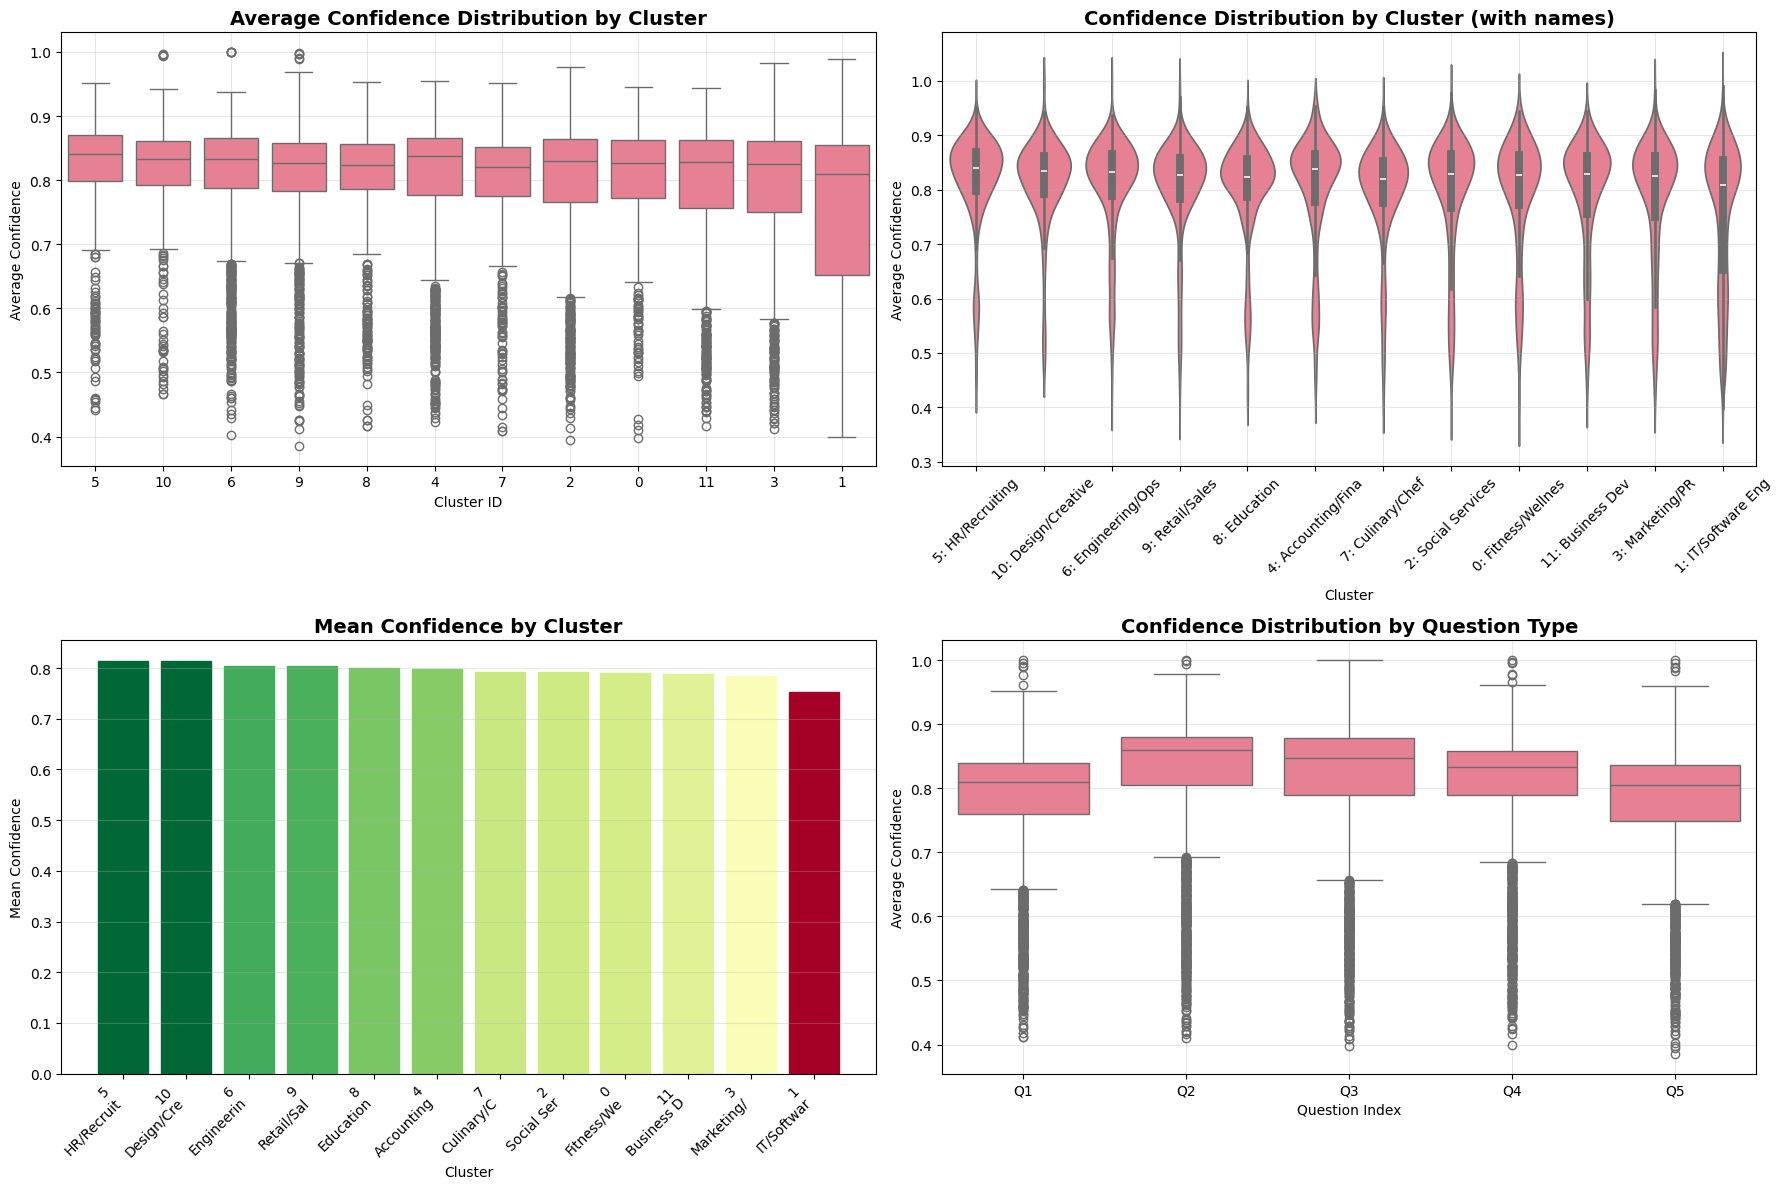

✓ Visualization saved to ../data/confidence_analysis.png


In [ ]:
# Visualize confidence distributions by cluster
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Box plot: Confidence by Cluster
ax1 = axes[0, 0]
cluster_order = results_df.groupby('cluster')['avg_confidence'].mean().sort_values(ascending=False).index
sns.boxplot(data=results_df, x='cluster', y='avg_confidence', order=cluster_order, ax=ax1)
ax1.set_title('Average Confidence Distribution by Cluster', fontsize=14, fontweight='bold')
ax1.set_xlabel('Cluster ID')
ax1.set_ylabel('Average Confidence')
ax1.tick_params(axis='x', rotation=0)
ax1.grid(True, alpha=0.3)

# 2. Violin plot: Confidence by Cluster with cluster names
ax2 = axes[0, 1]
results_df_plot = results_df.copy()
results_df_plot['cluster_label'] = results_df_plot.apply(
    lambda row: f"{row['cluster']}: {cluster_names.get(row['cluster'], 'Unknown')[:15]}", axis=1
)
cluster_label_order = results_df_plot.groupby('cluster_label')['avg_confidence'].mean().sort_values(ascending=False).index
sns.violinplot(data=results_df_plot, x='cluster_label', y='avg_confidence', order=cluster_label_order, ax=ax2)
ax2.set_title('Confidence Distribution by Cluster (with names)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Cluster')
ax2.set_ylabel('Average Confidence')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, alpha=0.3)

# 3. Bar plot: Mean Confidence by Cluster
ax3 = axes[1, 0]
cluster_means = results_df.groupby('cluster')['avg_confidence'].mean().sort_values(ascending=False)
bars = ax3.bar(range(len(cluster_means)), cluster_means.values)
ax3.set_xticks(range(len(cluster_means)))
ax3.set_xticklabels([f"{c}\n{cluster_names[c][:10]}" for c in cluster_means.index], rotation=45, ha='right')
ax3.set_title('Mean Confidence by Cluster', fontsize=14, fontweight='bold')
ax3.set_xlabel('Cluster')
ax3.set_ylabel('Mean Confidence')
ax3.grid(True, alpha=0.3, axis='y')

# Color bars by value
colors = plt.cm.RdYlGn([(v - cluster_means.min()) / (cluster_means.max() - cluster_means.min())
                         for v in cluster_means.values])
for bar, color in zip(bars, colors):
    bar.set_color(color)

# 4. Box plot: Confidence by Question Type
ax4 = axes[1, 1]
results_df_plot['question_label'] = results_df_plot['question_idx'].map(
    {i: f"Q{i+1}: {templates[i][:30]}..." for i in range(len(templates))}
)
sns.boxplot(data=results_df_plot, x='question_idx', y='avg_confidence', ax=ax4)
ax4.set_title('Confidence Distribution by Question Type', fontsize=14, fontweight='bold')
ax4.set_xlabel('Question Index')
ax4.set_ylabel('Average Confidence')
ax4.set_xticklabels([f"Q{i+1}" for i in range(len(templates))])
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../data/confidence_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualization saved to ../data/confidence_analysis.png")

In [ ]:
# Statistical tests to check if clusters have significantly different confidences
from scipy import stats

print("\n" + "="*80)
print("STATISTICAL ANALYSIS: DO CLUSTERS DIFFER IN CONFIDENCE?")
print("="*80)

# Prepare data for ANOVA
cluster_groups = [results_df[results_df['cluster'] == c]['avg_confidence'].values
                  for c in sorted(results_df['cluster'].unique())]

# Perform one-way ANOVA
f_stat, p_value = stats.f_oneway(*cluster_groups)
print(f"\nOne-Way ANOVA:")
print(f"  F-statistic: {f_stat:.4f}")
print(f"  P-value: {p_value:.6f}")
print(f"  Result: {'Significant differences between clusters' if p_value < 0.05 else 'No significant differences'}")

# Kruskal-Wallis test (non-parametric alternative)
h_stat, kw_p_value = stats.kruskal(*cluster_groups)
print(f"\nKruskal-Wallis H-test (non-parametric):")
print(f"  H-statistic: {h_stat:.4f}")
print(f"  P-value: {kw_p_value:.6f}")
print(f"  Result: {'Significant differences between clusters' if kw_p_value < 0.05 else 'No significant differences'}")

# Effect size (eta-squared for ANOVA)
grand_mean = results_df['avg_confidence'].mean()
ss_between = sum([len(group) * (group.mean() - grand_mean)**2 for group in cluster_groups])
ss_total = sum([(x - grand_mean)**2 for group in cluster_groups for x in group])
eta_squared = ss_between / ss_total if ss_total > 0 else 0
print(f"\nEffect Size (η²): {eta_squared:.4f}")
print(f"  Interpretation: {'Small' if eta_squared < 0.06 else 'Medium' if eta_squared < 0.14 else 'Large'} effect")

print("\n" + "="*80)


STATISTICAL ANALYSIS: DO CLUSTERS DIFFER IN CONFIDENCE?

One-Way ANOVA:
  F-statistic: 24.6773
  P-value: 0.000000
  Result: Significant differences between clusters

Kruskal-Wallis H-test (non-parametric):
  H-statistic: 172.9727
  P-value: 0.000000
  Result: Significant differences between clusters

Effect Size (η²): 0.0214
  Interpretation: Small effect



In [ ]:
# Example: View detailed results for a specific cluster
example_cluster = 1  # IT/Software Engineering

print(f"\n{'='*80}")
print(f"EXAMPLE RESULTS FOR CLUSTER {example_cluster}: {cluster_names[example_cluster]}")
print(f"{'='*80}\n")

cluster_results = results_df[results_df['cluster'] == example_cluster].head(5)

for idx, row in cluster_results.iterrows():
    print(f"Job: {row['job_name']}")
    print(f"Question: {row['question']}")
    print(f"Generated Answer: {row['generated_answer'][:200]}...")
    print(f"Average Confidence: {row['avg_confidence']:.4f}")
    print(f"Number of Tokens: {row['num_tokens']}")
    print(f"Token Logits (first 10): {row['token_logits'][:10]}")
    print("-" * 80)
    print()


EXAMPLE RESULTS FOR CLUSTER 1: IT/Software Eng

Job: HR SPECIALIST (INFORMATION SYSTEMS)           Experience     02/2013   -   12/2014     Company Name   －   City  ,   State    HR Specialist (Information Systems)        Permanent/FT Supervisor: Iris Murray (910-432-2392)  Served as Fort Bragg Installation Civilian Personnel Information Systems Manager with full responsibility for establishing and implementing automated personnel policy, providing advisory services, and resolving HR automation user issues. This included system access control, HR automation training administration and instruction, HR automation system software functionality and interface issues, hardware troubleshooting, installation and maintenance, and regulatory and procedural guidance, etc. Systems included: FASCLASS, AutoNoa, USA Staffing, Business Objects Applications (SAP Software), CPOL, DCPDS, CSU, eOPF, ASARS, etc.  Designed, constructed, tested, deployed, and maintained organizational SharePoint infrastructu

In [ ]:
def analyze_token_logits(results, index):
    """
    Analyze and display token-level logits for a specific result.

    Args:
        results: List of result dictionaries from generate_questions_with_logits_batched
        index: Index of the result to analyze
    """
    if index < 0 or index >= len(results):
        print(f"❌ Index {index} out of range. Valid range: 0-{len(results)-1}")
        return

    result = results[index]

    # Header
    print("\n" + "="*100)
    print(f"ANALYSIS FOR RESULT #{index}")
    print("="*100)

    # Metadata
    print(f"\n📋 Metadata:")
    print(f"  Job Name: {result['job_name'][:80]}")
    print(f"  Cluster: {result['cluster']} ({result['cluster_name']})")
    print(f"  Question Type: {result['question_idx']}")

    # Question
    print(f"\n❓ Question:")
    print(f"  {result['question']}")

    # Answer
    print(f"\n💬 Generated Answer:")
    print(f"  {result['generated_answer']}")

    # Statistics
    print(f"\n📊 Statistics:")
    print(f"  Average Confidence: {result['avg_confidence']:.4f}")
    print(f"  Number of Tokens: {result['num_tokens']}")
    print(f"  Min Logit: {min(result['token_logits']):.4f}")
    print(f"  Max Logit: {max(result['token_logits']):.4f}")

    # Decode individual tokens and show with logits
    print(f"\n🔍 Token-by-Token Analysis:")
    print(f"  {'Token':<30} {'Logit':>10} {'Bar':>40}")
    print(f"  {'-'*30} {'-'*10} {'-'*40}")

    # Tokenize the answer to get individual tokens
    answer_tokens = tokenizer.encode(result['generated_answer'], add_special_tokens=False)
    decoded_tokens = [tokenizer.decode([token]) for token in answer_tokens]

    # Match tokens with logits (they should be same length)
    for i, (token, logit) in enumerate(zip(decoded_tokens, result['token_logits'])):
        # Create visual bar
        bar_length = int(logit * 40)  # Scale to 40 chars max
        bar = '█' * bar_length

        # Color coding based on confidence
        if logit < 0.3:
            indicator = "🔴"  # Low confidence
        elif logit < 0.7:
            indicator = "🟡"  # Medium confidence
        else:
            indicator = "🟢"  # High confidence

        # Escape special characters for display
        token_display = repr(token)[1:-1][:28]  # Remove quotes and limit length

        print(f"  {token_display:<30} {logit:>10.4f} {bar:<40} {indicator}")

    # Find lowest and highest confidence tokens
    sorted_indices = sorted(range(len(result['token_logits'])),
                           key=lambda i: result['token_logits'][i])

    print(f"\n🔻 Lowest Confidence Tokens (Top 5):")
    for i in sorted_indices[:5]:
        if i < len(decoded_tokens):
            token = decoded_tokens[i]
            logit = result['token_logits'][i]
            print(f"  Token: {repr(token)[1:-1]:<30} Logit: {logit:.4f}")

    print(f"\n🔺 Highest Confidence Tokens (Top 5):")
    for i in sorted_indices[-5:][::-1]:
        if i < len(decoded_tokens):
            token = decoded_tokens[i]
            logit = result['token_logits'][i]
            print(f"  Token: {repr(token)[1:-1]:<30} Logit: {logit:.4f}")

    print("\n" + "="*100 + "\n")

# Example usage
print("Usage: analyze_token_logits(results, index)")
print(f"Available indices: 0 to {len(results)-1}")
print("\nExample: analyze_token_logits(results, 0)")

Usage: analyze_token_logits(results, index)
Available indices: 0 to 24

Example: analyze_token_logits(results, 0)


In [ ]:
analyze_token_logits(results, 1)


ANALYSIS FOR RESULT #1

📋 Metadata:
  Job Name: HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR
  Cluster: 5 (HR/Recruiting)
  Question Type: 1

❓ Question:
  What is the average salary for a HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR?

💬 Generated Answer:
  What is the average salary for a HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR?
Provide a direct answer:

The average salary for an HR Administrator/Marketing Associate can vary greatly depending on factors such as location, industry, and level of experience. According to data from Glassdoor, the average base salary for an HR Administrator in the United States is around $45,000 per year, while the average base salary for a Marketing Associate is around $50,000 per year. However, these numbers can be higher or lower depending on the specific job

📊 Statistics:
  Average Confidence: 0.8941
  Number of Tokens: 100
  Min Logit: 0.2244
  Max Logit: 1.0000

🔍 Token-by-Token Analysis:
  Token                  